<a href="https://colab.research.google.com/github/ilovemadfenmobile18-lab/doc-classification-ml/blob/main/notebooks/01_eda_and_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
# ИМПОРТ БИБЛИОТЕК И НАСТРОЙКА ОКРУЖЕНИЯ

!pip install pymorphy3 scikit-learn pandas matplotlib seaborn joblib -q

import re
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pymorphy3

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# Фиксация случайного состояния для воспроизводимости
RANDOM_STATE = 42
print("Окружение настроено успешно.")

Окружение настроено успешно.


ТЕХНИЧЕСКИЙ ПАСПОРТ ДАТАСЕТА
Всего документов в корпусе: 120
Пропущенных значений (NaN): 0
Полных дубликатов текста:   0

Распределение по департаментам:
department
Бухгалтерия    30
Кадры          30
IT             30
Юротдел        30
Name: count, dtype: int64


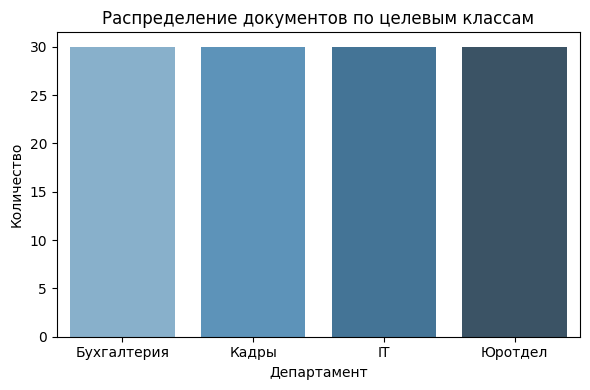

In [17]:
# ПАСПОРТ ДАННЫХ И РАЗВЕДОЧНЫЙ АНАЛИЗ (EDA)

df = pd.read_csv('dataset.csv')

print("ТЕХНИЧЕСКИЙ ПАСПОРТ ДАТАСЕТА")
print(f"Всего документов в корпусе: {len(df)}")
print(f"Пропущенных значений (NaN): {df.isna().sum().sum()}")
print(f"Полных дубликатов текста:   {df['text'].duplicated().sum()}")
print("\nРаспределение по департаментам:")
print(df['department'].value_counts())

# Визуализация распределения классов
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='department', hue='department', palette='Blues_d', legend=False)
plt.title('Распределение документов по целевым классам')
plt.xlabel('Департамент')
plt.ylabel('Количество')
plt.tight_layout()
plt.show()

In [19]:
# КОНВЕЙЕР ПРЕДОБРАБОТКИ ТЕКСТА (DATA PREPROCESSING)


morph = pymorphy3.MorphAnalyzer()

def preprocess_text(text: str) -> str:
    """Очистка от пунктуации, перевод в нижний регистр и морфологическая лемматизация."""
    clean = re.sub(r'[^а-яё\s]', ' ', str(text).lower())
    words = clean.split()
    lemmas = [morph.parse(w)[0].normal_form for w in words if len(w) > 2]
    return ' '.join(lemmas)

df['clean_text'] = df['text'].apply(preprocess_text)

print("Пример обработки:")
print(f"До:    {df['text'].iloc[0]}")
print(f"После: {df['clean_text'].iloc[0]}")

Пример обработки:
До:    Просим подписать прилагаемый акт сверки взаимных расчетов за третий квартал 2026 года и вернуть один экземпляр с печатью.
После: просить подписать прилагать акт сверка взаимный расчёт третий квартал год вернуть один экземпляр печать


In [20]:
# РАЗБИЕНИЕ ВЫБОРКИ (TRAIN / VALIDATION / TEST)

# 1. Отделяем тестовую выборку (15%)
train_val_df, test_df = train_test_split(
    df, test_size=0.15, random_state=RANDOM_STATE, stratify=df['department']
)

# 2. Оставшиеся данные делим на Train (70% от исходного) и Val (15% от исходного)
val_relative_size = 0.15 / (1.0 - 0.15)
train_df, val_df = train_test_split(
    train_val_df, test_size=val_relative_size, random_state=RANDOM_STATE, stratify=train_val_df['department']
)

print(f"Обучающая выборка (Train):     {len(train_df)} документов")
print(f"Валидационная выборка (Val):   {len(val_df)} документов")
print(f"Отложенная тестовая (Test):    {len(test_df)} документов")

Обучающая выборка (Train):     84 документов
Валидационная выборка (Val):   18 документов
Отложенная тестовая (Test):    18 документов


In [21]:
# ВЕКТОРИЗАЦИЯ TF-IDF (УНИГРАММЫ И БИГРАММЫ)

vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=3000)

X_train = vectorizer.fit_transform(train_df['clean_text'])
X_val = vectorizer.transform(val_df['clean_text'])
X_test = vectorizer.transform(test_df['clean_text'])

y_train = train_df['department']
y_val = val_df['department']
y_test = test_df['department']

print(f"Размерность матрицы признаков: {X_train.shape[1]} признаков (леммы и биграммы)")

Размерность матрицы признаков: 704 признаков (леммы и биграммы)


In [22]:
# СРАВНИТЕЛЬНЫЙ АНАЛИЗ МОДЕЛЕЙ И GRIDSEARCHCV

candidate_models = {
    "Logistic Regression": {
        "model": LogisticRegression(random_state=RANDOM_STATE),
        "params": {"C": [0.1, 1.0, 10.0]}
    },
    "Linear SVC": {
        "model": LinearSVC(random_state=RANDOM_STATE),
        "params": {"C": [0.1, 0.5, 1.0, 5.0]}
    },
    "Multinomial Naive Bayes": {
        "model": MultinomialNB(),
        "params": {"alpha": [0.01, 0.1, 1.0]}
    },
    "Random Forest": {
        "model": RandomForestClassifier(random_state=RANDOM_STATE),
        "params": {"n_estimators": [50, 100], "max_depth": [5, 10, None]}
    }
}

experiment_results = []
tuned_models = {}

# 1. Тюнинг и оценка моделей
for name, config in candidate_models.items():
    grid = GridSearchCV(config["model"], config["params"], scoring="f1_macro", cv=3, n_jobs=-1)
    grid.fit(X_train, y_train)
    best_est = grid.best_estimator_
    tuned_models[name] = best_est

    val_preds = best_est.predict(X_val)
    experiment_results.append({
        "Модель": name,
        "Лучшие параметры": str(grid.best_params_),
        "Accuracy (Val)": round(accuracy_score(y_val, val_preds), 4),
        "Macro-F1 (Val)": round(f1_score(y_val, val_preds, average="macro"), 4)
    })

# 2. Добавление Baseline
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_val_preds = dummy.predict(X_val)
experiment_results.insert(0, {
    "Модель": "Baseline (Most Frequent)",
    "Лучшие параметры": "strategy='most_frequent'",
    "Accuracy (Val)": round(accuracy_score(y_val, dummy_val_preds), 4),
    "Macro-F1 (Val)": round(f1_score(y_val, dummy_val_preds, average="macro"), 4)
})

# Сводная таблица
df_experiments = pd.DataFrame(experiment_results)
display(df_experiments)

,Модель,Лучшие параметры,Accuracy (Val),Macro-F1 (Val)
0,Baseline (Most Frequent),strategy='most_frequent',0.2222,0.0909
1,Logistic Regression,{'C': 0.1},0.9444,0.9365
2,Linear SVC,{'C': 1.0},0.9444,0.9365
3,Multinomial Naive Bayes,{'alpha': 1.0},0.9444,0.9365
4,Random Forest,"{'max_depth': 10, 'n_estimators': 100}",0.8333,0.8264


ФИНАЛЬНЫЙ ОТЧЕТ ПО КЛАССАМ (TEST SET)
              precision    recall  f1-score   support

          IT       1.00      0.60      0.75         5
 Бухгалтерия       1.00      1.00      1.00         4
       Кадры       0.71      1.00      0.83         5
     Юротдел       1.00      1.00      1.00         4

    accuracy                           0.89        18
   macro avg       0.93      0.90      0.90        18
weighted avg       0.92      0.89      0.88        18



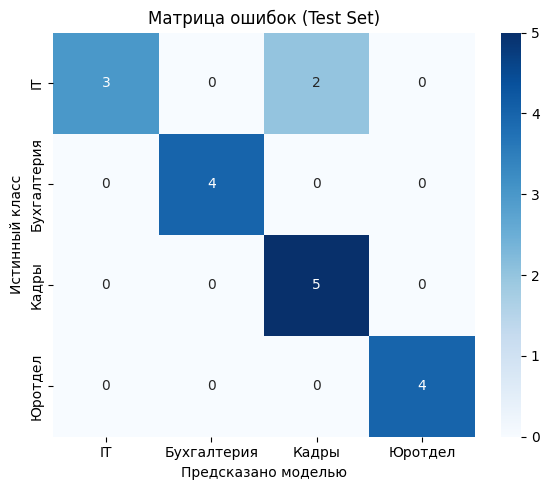

In [24]:
# ФИНАЛЬНЫЙ ТЕСТ И МАТРИЦА ОШИБОК (TEST SET)

best_model = tuned_models["Linear SVC"]
y_test_pred = best_model.predict(X_test)

print("ФИНАЛЬНЫЙ ОТЧЕТ ПО КЛАССАМ (TEST SET)")
print(classification_report(y_test, y_test_pred))

# Построение матрицы ошибок
cm = confusion_matrix(y_test, y_test_pred, labels=best_model.classes_)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=best_model.classes_,
            yticklabels=best_model.classes_)
plt.title('Матрица ошибок (Test Set)')
plt.xlabel('Предсказано моделью')
plt.ylabel('Истинный класс')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()

In [25]:
# АНАЛИЗ 10 ХАРАКТЕРНЫХ ОШИБОК И ГРАНИЧНЫХ СЛУЧАЕВ

stress_test_cases = [
    {"text": "Срочно: прошу сбросить пароль от доменной учетной записи", "true_dept": "IT", "note": "Коллизия вокруг биграммы 'учетная запись'"},
    {"text": "Прошу сбросить пароль от доменной учетной записи сотрудника", "true_dept": "IT", "note": "Доминирование кадровой лексики над системной"},
    {"text": "Прошу оплатить счет на продление лицензий корпоративного антивируса", "true_dept": "Бухгалтерия", "note": "Пересечение маркеров IT и Бухгалтерии"},
    {"text": "Согласовать договор на поставку серверных стоек и коммутаторов", "true_dept": "Юротдел", "note": "Смежная лексика Юротдела (договор) и IT (серверы)"},
    {"text": "Служебная записка о премировании ведущего инженера-программиста", "true_dept": "Кадры", "note": "Конфликт терминологии премирования и должности"},
    {"text": "Претензия от поставщика о задержке оплаты по акту выполненных работ", "true_dept": "Юротдел", "note": "Пересечение претензионной работы и взаиморасчетов"},
    {"text": "Выдать справку о доходах по форме 2-НДФЛ для оформления визы", "true_dept": "Бухгалтерия", "note": "Запрос справки сотрудником (Кадры vs Расчет зарплаты)"},
    {"text": "Компьютер не видит флешку", "true_dept": "IT", "note": "Крайне короткий запрос с дефицитом признаков"},
    {"text": "Прошу принять на работу нового системного администратора в отдел инфраструктуры", "true_dept": "Кадры", "note": "Кадровый приказ с упоминанием ИТ-должности"},
    {"text": "Расторгнуть трудовой договор с сотрудником в связи с нарушением регламента", "true_dept": "Кадры", "note": "Трудовые отношения на стыке кадров и регламентов"}
]

error_rows = []
for item in stress_test_cases:
    clean = preprocess_text(item["text"])
    vec = vectorizer.transform([clean])
    pred = best_model.predict(vec)[0]
    error_rows.append({
        "Текст обращения": item["text"],
        "Истинный класс": item["true_dept"],
        "Прогноз": pred,
        "Статус": "Корректно" if pred == item["true_dept"] else "Ошибочно",
        "Причина": item["note"]
    })

df_errors = pd.DataFrame(error_rows)
display(df_errors)

,Текст обращения,Истинный класс,Прогноз,Статус,Причина
0,Срочно: прошу сбросить пароль от доменной учетной записи,IT,IT,Корректно,Коллизия вокруг биграммы 'учетная запись'
1,Прошу сбросить пароль от доменной учетной записи сотрудника,IT,IT,Корректно,Доминирование кадровой лексики над системной
2,Прошу оплатить счет на продление лицензий корпоративного антивируса,Бухгалтерия,Бухгалтерия,Корректно,Пересечение маркеров IT и Бухгалтерии
3,Согласовать договор на поставку серверных стоек и коммутаторов,Юротдел,IT,Ошибочно,Смежная лексика Юротдела (договор) и IT (серверы)
4,Служебная записка о премировании ведущего инженера-программиста,Кадры,Кадры,Корректно,Конфликт терминологии премирования и должности
5,Претензия от поставщика о задержке оплаты по акту выполненных работ,Юротдел,Бухгалтерия,Ошибочно,Пересечение претензионной работы и взаиморасчетов
6,Выдать справку о доходах по форме 2-НДФЛ для оформления визы,Бухгалтерия,Кадры,Ошибочно,Запрос справки сотрудником (Кадры vs Расчет зарплаты)
7,Компьютер не видит флешку,IT,IT,Корректно,Крайне короткий запрос с дефицитом признаков
8,Прошу принять на работу нового системного администратора в отдел инфраструктуры,Кадры,IT,Ошибочно,Кадровый приказ с упоминанием ИТ-должности
9,Расторгнуть трудовой договор с сотрудником в связи с нарушением регламента,Кадры,Юротдел,Ошибочно,Трудовые отношения на стыке кадров и регламентов


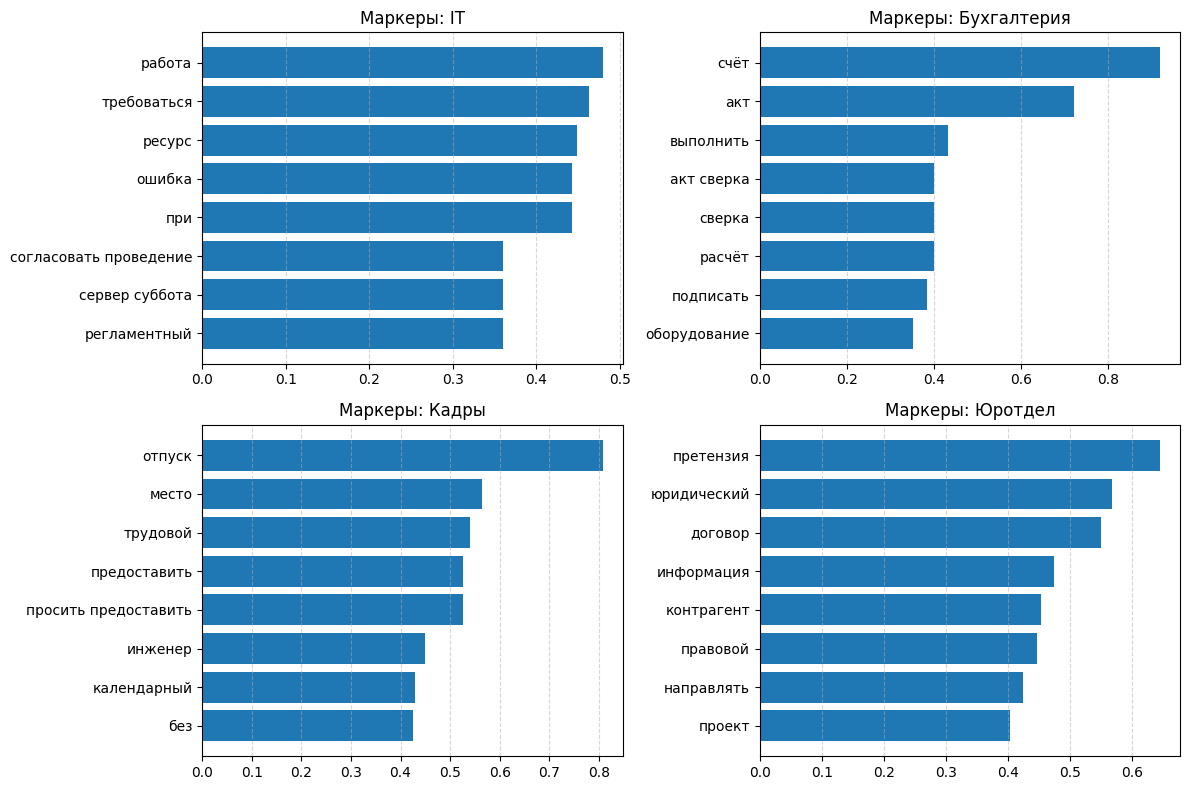

Среднее время обработки одного документа: 0.922 мс
Пропускная способность: 1084668.7 документов/сек


In [26]:
# ИНТЕРПРЕТАЦИЯ ПРИЗНАКОВ И ЗАМЕР ПРОИЗВОДИТЕЛЬНОСТИ (LATENCY)

# 1. Интерпретация признаков LinearSVC
feature_names = np.array(vectorizer.get_feature_names_out())
plt.figure(figsize=(12, 8))
for idx, label in enumerate(best_model.classes_):
    weights = best_model.coef_[idx]
    top_idx = np.argsort(weights)[-8:]
    plt.subplot(2, 2, idx + 1)
    plt.barh(feature_names[top_idx], weights[top_idx], color='#1f77b4')
    plt.title(f'Маркеры: {label}')
    plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300)
plt.show()

# 2. Замер времени инференса на CPU
sample_clean = preprocess_text("Прошу предоставить очередной оплачиваемый отпуск на 14 дней")
start = time.perf_counter()
for _ in range(1000):
    _ = best_model.predict(vectorizer.transform([sample_clean]))
latency_ms = ((time.perf_counter() - start) / 1000) * 1000

print(f"Среднее время обработки одного документа: {latency_ms:.3f} мс")
print(f"Пропускная способность: {1000 / (latency_ms / 1000):.1f} документов/сек")

In [27]:
# СБОРКА И ЭКСПОРТ ЕДИНОГО АРТЕФАКТА МОДЕЛИ ДЛЯ ПРОДАКШНА

# Калибровка вероятностей для линейной модели
calibrated_svc = CalibratedClassifierCV(estimator=best_model, cv=3)

full_pipeline = Pipeline([
    ('tfidf', vectorizer),
    ('clf', calibrated_svc)
])

# Обучаем весь пайплайн на предобработанных обучающих текстах
full_pipeline.fit(train_df['clean_text'], y_train)

# Сохраняем артефакт на диск
joblib.dump(full_pipeline, 'model_pipeline.joblib')
print("Артефакт 'model_pipeline.joblib' успешно сформирован и сохранен.")

Артефакт 'model_pipeline.joblib' успешно сформирован и сохранен.
